# Dataset Acquisition and Description

## Imports

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

## Source

"The Dataset is based on 3,004 images collected by the Pancam instruments mounted on the Oppurtunity and Spirit rovers from NASA's Mars Exploration Rovers (MER). Using rotation, skewing and shearing augmentation methods to increase total collection to 70,864" - [MER Opportunity and Spirit Rovers Pancam Images Labeled Data Set](https://zenodo.org/records/4302760)

This datasets suits a Convalutional Neural Network Model due to its capabilities with labeled image data in which the convalutional layers will learn

It is a multi label dataset meaning each image has multiple labels to describe the image

In [5]:
# Read in text files with the filenames and labels 
def read_txt_files(path):

    rows = []

    with open(path, encoding='UTF-8') as f:
        
        for line in f:

            line = line.strip()

            filename = line.split(",")[0]

            labels = line.split(",")[1:]

            rows.append({'filename':filename, 'labels':labels})

        data = pd.DataFrame(rows)

        return data

test_data = read_txt_files('rover_image_classification/mer-labeled-data-set-v1.1.0/test-set-v1.1.0.txt')

train_data = read_txt_files('rover_image_classification/mer-labeled-data-set-v1.1.0/train-set-v1.1.0.txt')

val_data = read_txt_files('rover_image_classification/mer-labeled-data-set-v1.1.0/val-set-v1.1.0.txt')

In [6]:
# Around 30 rows in the train data are not in the images so will drop these rows doesnt seem to be the same in val and test data so will leave as is there
image_dir = Path('rover_image_classification/mer-labeled-data-set-v1.1.0/images')

folder_files = []
for f in image_dir.iterdir():

    folder_files.append(f.name)

folder_files = pd.DataFrame(folder_files,columns=['filename'])

drop_train_data = train_data[~train_data['filename'].isin(folder_files['filename'])].index

print('Number of Files not in Train Data', len(drop_train_data))

train_data.drop(drop_train_data,inplace=True)

# No missing files in these datasets
print('Missing Files in Val Data: ', len(val_data[~val_data['filename'].isin(folder_files['filename'])]))
print('Missing Files in Test Data: ', len(test_data[~test_data['filename'].isin(folder_files['filename'])]))

# Filtering the data to only contain the original images of the dataset
orig_train_data = train_data[train_data['filename'].str.endswith('img.jpg')].copy()
orig_test_data = test_data[test_data['filename'].str.endswith('img.jpg')].copy()
orig_val_data = val_data[val_data['filename'].str.endswith('img.jpg')].copy()

# Loading images and returning arrays of the image data on the original pictures
def load_images(path):

    image = Image.open(image_dir/path)

    return np.array(image)

orig_train_data['images'] = orig_train_data['filename'].apply(load_images)
orig_test_data['images'] = orig_test_data['filename'].apply(load_images)
orig_val_data['images'] = orig_val_data['filename'].apply(load_images)

# Getting the properties of each image
def get_properties(images):

    with Image.open(image_dir/images) as im:

        return pd.Series({'width':im.width, 'height':im.height, 'mode':im.mode})

orig_train_data_properties = orig_train_data['filename'].apply(get_properties)
orig_test_data_properties = orig_test_data['filename'].apply(get_properties)
orig_val_data_properties = orig_val_data['filename'].apply(get_properties)

orig_train_data = orig_train_data.join(orig_train_data_properties)
orig_test_data = orig_test_data.join(orig_test_data_properties)
orig_val_data = orig_val_data.join(orig_val_data_properties)

# Concatenating all data into one df to perform analysis on all data
data = pd.concat([orig_train_data, orig_val_data, orig_test_data], ignore_index=True)

Number of Files not in Train Data 55986
Missing Files in Val Data:  14136
Missing Files in Test Data:  742


FileNotFoundError: [Errno 2] No such file or directory: 'rover_image_classification\\mer-labeled-data-set-v1.1.0\\images\\1p128368623mrd0200p2217l2m1.img.jpg'

## Size

In [ ]:
print('Size of Data: ', len(data))
print('Size of Train: ', len(orig_train_data))
print('Size of Test: ', len(orig_test_data))
print('Size of Val: ', len(orig_val_data))

Size of Data:  3003
Size of Train:  1805
Size of Test:  742
Size of Val:  456


- In total we have 3003 original images with one image dropped due to a file missing in the dataset
- The dataset is already split with a train, test and validation split of 60/25/15
- We will work with just the original images first as the augmented images are augmented from the original images this will also save computational resources during the EDA process

## Structure

In [ ]:
print('Shape of Data: ', data.shape)
print('Shape of Train: ', data.shape)
print('Shape of Test: ', data.shape)
print('Shape of Val: ', data.shape)

Shape of Data:  (3003, 6)
Shape of Train:  (3003, 6)
Shape of Test:  (3003, 6)
Shape of Val:  (3003, 6)


- We see there is a total of 3003 rows and 6 columns in each dataset

## Variables

In [ ]:
data.head()

,filename,labels,images,width,height,mode
0,1p128287268mrd0000p2303l2m1.img.jpg,"[ Rover Deck, Dunes/Ripples, Soil, Spherule...","[[62, 54, 48, 51, 59, 61, 54, 45, 45, 52, 60, ...",1024,1024,L
1,1p128288415mrd0000p2303l2m1.img.jpg,"[ Rocks (misc), Dunes/Ripples, Soil, Spheru...","[[116, 135, 139, 133, 135, 134, 129, 129, 137,...",1024,1024,L
2,1p128289213mrd0000p2303l2m1.img.jpg,"[ Soil, Spherules, Nearby Surface]","[[68, 55, 106, 97, 112, 123, 107, 106, 110, 10...",1024,1024,L
3,1p129341281mrd0300p2376l2m1.img.jpg,"[ Rock Outcrops, Clasts, Rock (Linear Featur...","[[108, 125, 141, 147, 149, 147, 135, 120, 133,...",1024,1024,L
4,1p129341947mrd0300p2376l2m1.img.jpg,"[ Rock Outcrops, Rock (Linear Features), Soi...","[[119, 139, 140, 129, 130, 136, 140, 146, 154,...",1024,1024,L


In [ ]:
orig_train_data.head()

,filename,labels,images,width,height,mode
31,1p128287268mrd0000p2303l2m1.img.jpg,"[ Rover Deck, Dunes/Ripples, Soil, Spherule...","[[62, 54, 48, 51, 59, 61, 54, 45, 45, 52, 60, ...",1024,1024,L
62,1p128288415mrd0000p2303l2m1.img.jpg,"[ Rocks (misc), Dunes/Ripples, Soil, Spheru...","[[116, 135, 139, 133, 135, 134, 129, 129, 137,...",1024,1024,L
93,1p128289213mrd0000p2303l2m1.img.jpg,"[ Soil, Spherules, Nearby Surface]","[[68, 55, 106, 97, 112, 123, 107, 106, 110, 10...",1024,1024,L
124,1p129341281mrd0300p2376l2m1.img.jpg,"[ Rock Outcrops, Clasts, Rock (Linear Featur...","[[108, 125, 141, 147, 149, 147, 135, 120, 133,...",1024,1024,L
155,1p129341947mrd0300p2376l2m1.img.jpg,"[ Rock Outcrops, Rock (Linear Features), Soi...","[[119, 139, 140, 129, 130, 136, 140, 146, 154,...",1024,1024,L


In [ ]:
orig_test_data.head()

,filename,labels,images,width,height,mode
0,1p128368623mrd0200p2217l2m1.img.jpg,"[ Dunes/Ripples, Soil, Distant Vista, Sky]","[[118, 124, 128, 126, 126, 127, 127, 124, 127,...",1024,1024,L
1,1p128369364mrd0200p2217l2m1.img.jpg,"[ Clasts, Soil, Nearby Surface]","[[116, 140, 138, 120, 124, 142, 148, 147, 149,...",1024,1024,L
2,1p128369598mrd0200p2217l2m1.img.jpg,"[ Rock Outcrops, Clasts, Rock (Linear Featur...","[[116, 164, 166, 159, 161, 158, 166, 170, 183,...",1024,1024,L
3,1p128370308mrd0200p2218l2m1.img.jpg,"[ Rock Outcrops, Rock (Linear Features), Sph...","[[119, 142, 149, 142, 142, 140, 138, 142, 145,...",1024,1024,L
4,1p128370471mrd0200p2218l2m1.img.jpg,"[ Soil, Sky]","[[118, 124, 128, 126, 126, 127, 127, 124, 128,...",1024,1024,L


In [ ]:
orig_val_data.head()

,filename,labels,images,width,height,mode
0,1p128541565mrd0205p2353l2m1.img.jpg,"[ Rock Outcrops, Rocks (misc), Dunes/Ripples...","[[120, 152, 151, 149, 150, 146, 150, 143, 149,...",1024,1024,L
31,1p128546210mrd0205p2357l2m1.img.jpg,"[ Soil, Spherules, Sky, Nearby Surface]","[[121, 140, 143, 136, 138, 139, 135, 137, 140,...",1024,1024,L
62,1p128551095mrd0205p2701l2m1.img.jpg,[ Sky],"[[118, 149, 148, 147, 149, 146, 151, 144, 147,...",1024,1024,L
93,1p128995026mrd0224p2512l2m1.img.jpg,"[ Arm Hardware, Soil, Spherules, Nearby Sur...","[[26, 26, 26, 26, 26, 26, 26, 26, 22, 20, 19, ...",1024,1024,L
124,1p129074625mrd0224p2370l2m1.img.jpg,"[ Clasts, Soil, Nearby Surface]","[[117, 133, 138, 127, 123, 131, 131, 122, 121,...",1024,1024,L


We see all three datasets have the same variables as described below:
- Filename - Name of the image file
- Labels - Labels of the Image with multiple labels per image
- Images - Array of the image values
- Width - Width of the Image
- Height - Height of the Image
- Mode - How each pixel is stored 

## Key Characteristics

### Labels Column

In [ ]:
data['labels'].value_counts()

labels
[ Rock Outcrops,  Clasts,  Rock (Linear Features),  Soil,  Nearby Surface]                                181
[ Rock Outcrops,  Clasts,  Soil,  Nearby Surface]                                                         116
[ Rock Outcrops,  Rock (Linear Features),  Soil,  Spherules,  Nearby Surface]                              99
[ Rock Outcrops,  Float Rocks,  Clasts,  Soil,  Nearby Surface]                                            80
[ Float Rocks,  Clasts,  Soil,  Nearby Surface]                                                            64
                                                                                                         ... 
[ Rover Deck,  Clasts,  Soil,  Nearby Surface,  Rover Parts,  Artifacts]                                    1
[ Float Rocks,  Clasts,  Distant Vista,  Sky]                                                               1
[ Rover Deck,  Other Hardware,  Rover Tracks,  Clasts,  Soil,  Nearby Surface,  Rover Parts]                1
[ R

- We can see from the labels column value counts that it contains multiple labels per image per row stored as an array

<Axes: xlabel='labels'>

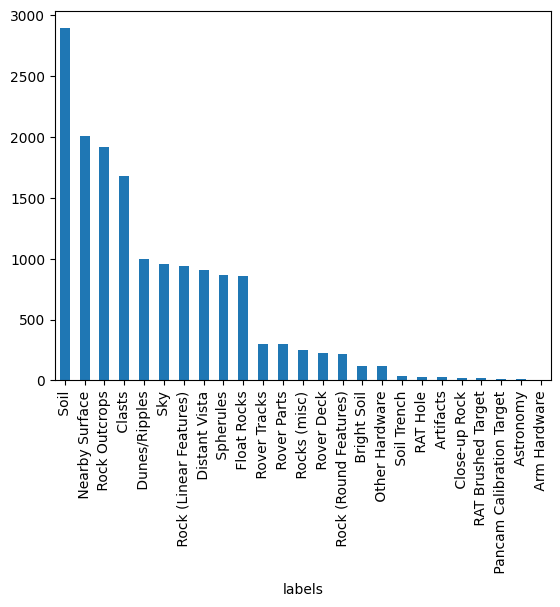

In [ ]:
data.labels.explode().value_counts().plot(kind='bar')

- Looking at the individual values we see an extremely high amount of Soil values, followed by Nearby surface, Rock Outcrops and Clasts
- With the likes of Astronomy, Arm Hardware and Pancam Callibration Target having a lot lower values

<Axes: xlabel='labels'>

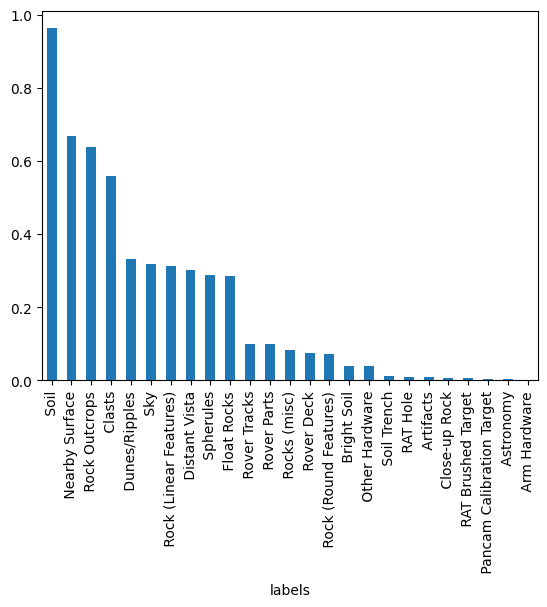

In [ ]:
(data.labels.explode().value_counts() / len(data)).plot(kind='bar')

### Images Column

In [ ]:
# Creating a np array of 256 zeros and adding the values of the image values into this array to plot the distribution
total = np.zeros(256, dtype=np.int64)
for img in data['images']:
    total += np.bincount(img.ravel(), minlength=256)

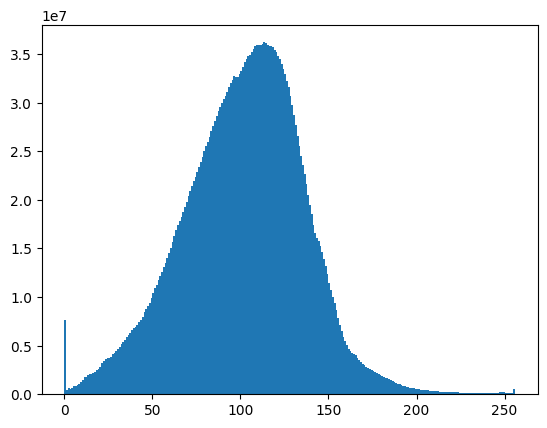

In [ ]:
plt.stairs(total, np.arange(257), fill=True)
plt.show()

- We can see from this plot that the image values follow a normal distribution with a clear spike at 0 due to the number of dark values

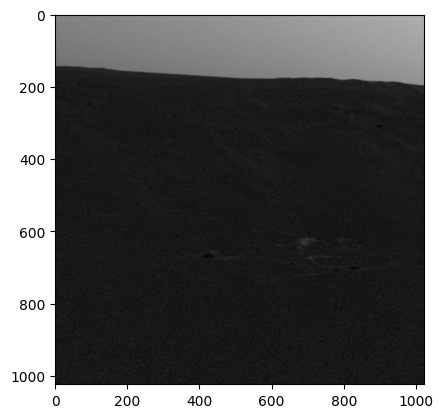

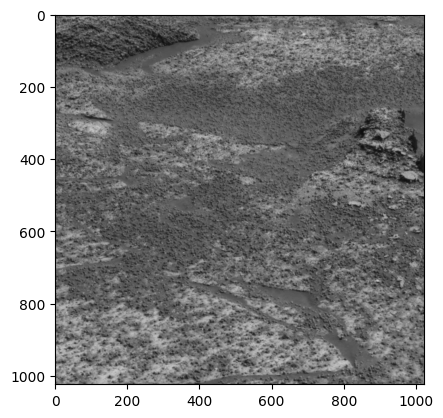

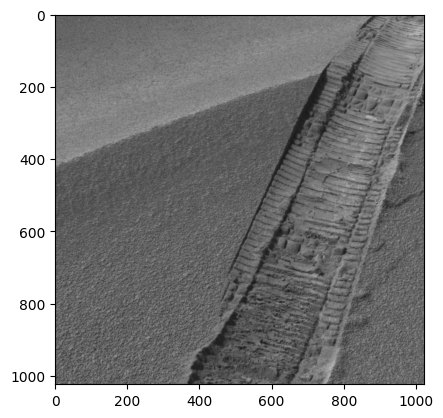

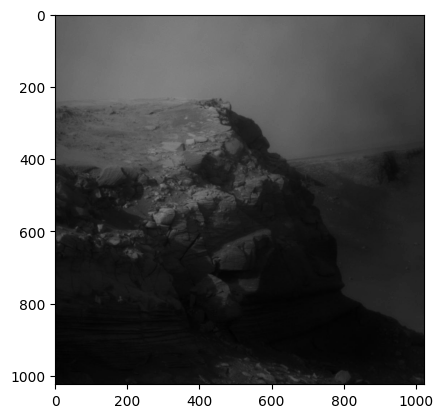

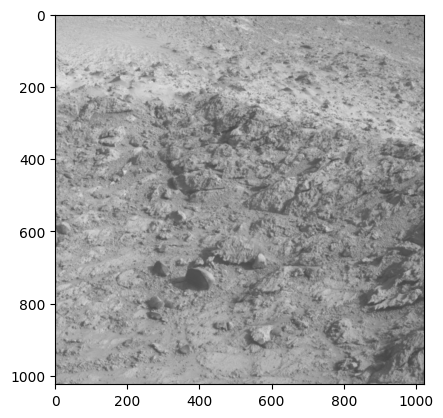

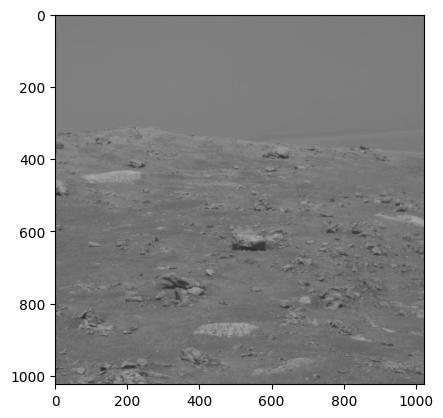

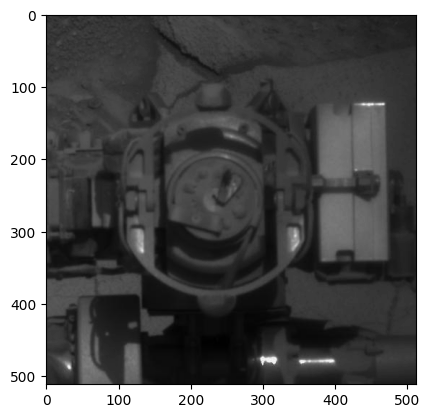

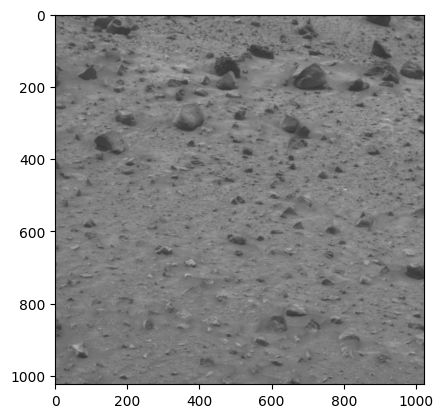

In [ ]:
# Showing examples of the images
images = [1,100,200,500,1000,2000,2500,3000]

for i in images:

    plt.imshow(data['images'][i], cmap='grey')

    plt.show()

- We can see that the images have a variety of pictures from the Mars expedition 
- Showing features such as rocks, machines, tracks and dunes
- We also see that all of the images are dark coloured

### Width, Height and Mode columns

In [ ]:
data['width'].value_counts()

width
1024    2750
512      253
Name: count, dtype: int64

In [ ]:
data['height'].value_counts()

height
1024    2750
512      253
Name: count, dtype: int64

In [ ]:
data['mode'].value_counts()

mode
L    3003
Name: count, dtype: int64

In [ ]:
data[['width', 'height', 'mode']].value_counts()

width  height  mode
1024   1024    L       2750
512    512     L        253
Name: count, dtype: int64

- We see here that there is a mixture of both 1024x1024 and 512x512 Images inside the dataset
- All Images are stored with mode L due to the images being greyscale

## Input Features and Target Variables

Based on the analysis and nature of the dataset the variables for training will be as follows:
- Target Variable: Labels
- Input Features: Images

## Justification

The images contain geoligical featurs that out model aims to identify, the strengths of the datasets is that it contains predefined labels, lots of imahes and existing validation, training and testing splits. 

## Conclusion

The main goal of this project is to apply a classification model to this dataset containing thousands of multi class labeled images so that it can predict what the image shows based on the features of the image 

Based on the analysis this dataset gives us 3000 original images and around 70,000 augmented images to work with to build a CNN that can predict multiple labels based on the image such as soil, rocks, dunes etc.